# A sensor array through PCA: can we see the gas classes?

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/unsupervised-learning/01-pca-gas-sensor-array.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

A gas sensor array produces a **multivariate fingerprint**: many measurements respond together when a gas is present. We will use a real sensor-array dataset to ask whether a two-dimensional view of those measurements makes the gas classes easier to recognize.

The source file is not a collection of raw voltage traces: it contains 128 response summaries derived from 16 metal-oxide sensors. We will inspect all 128, then use the steady-state ΔR reading from each sensor (16 values total) for a compact, interpretable comparison. The UCI dataset includes six gases and measurements collected over multiple batches as the sensors aged. [UCI Gas Sensor Array Drift dataset](https://archive.ics.uci.edu/dataset/224/gas+sensor+array+drift+dataset)

## What we will do

1. Download and inspect one batch of the original UCI data.
2. Use a forest-style classifier to rank the 16 sensor readings, then inspect the two highest-ranked raw measurements.
3. Standardize the 16 steady-state sensor readings and fit PCA without using gas labels.
4. Compare the same simple classifier using the two raw features and the first 2, 3, or 4 PCs.
5. Make the key comparison plot: the two raw-feature view beside the PC1–PC2 view.

Gas labels are used to fit the feature-ranking model and, later, to color plots and evaluate classifiers. **PCA itself never sees the labels.**

## 1. Download the data and inspect its raw format

The file is distributed in LIBSVM text format. Each line starts with a numeric gas label and then lists feature-number/value pairs. UCI organizes the measurements into batches; here we take Batch 1 (445 samples) so the first example stays compact and does not mix in longer-term sensor drift across batches.

Each of the 16 sensors contributes eight response summaries: steady-state resistance change (ΔR), normalized ΔR, and six summaries of the rising and falling response. That gives 128 features per sample. We will first inspect the complete feature vector, then focus the model comparison on one measurement per sensor—the steady-state ΔR. The [UCI documentation](https://archive.ics.uci.edu/dataset/224/gas+sensor+array+drift+dataset) describes the feature layout, class labels, and batch structure.

In [1]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_svmlight_file
from sklearn.decomposition import PCA
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
RANDOM_STATE = 4520

GAS_NAMES = {
    1: "Ethanol",
    2: "Ethylene",
    3: "Ammonia",
    4: "Acetaldehyde",
    5: "Acetone",
    6: "Toluene",
}
GAS_ORDER = list(GAS_NAMES.values())
GAS_PALETTE = dict(zip(GAS_ORDER, sns.color_palette("colorblind", n_colors=6)))

In [2]:
# Download the public UCI archive into memory; nothing needs to be uploaded to Drive.
DATA_URL = (
    "https://archive.ics.uci.edu/static/public/224/"
    "gas%2Bsensor%2Barray%2Bdrift%2Bdataset.zip"
)

with urlopen(DATA_URL, timeout=60) as response:
    archive_bytes = response.read()

with ZipFile(BytesIO(archive_bytes)) as archive:
    # The archive includes ten time-ordered batch files.
    batch1_bytes = archive.read("Dataset/batch1.dat")

# Keep a decoded copy so we can inspect the original text line.
batch1_text = batch1_bytes.decode("utf-8")

# load_svmlight_file parses the label and the indexed feature:value pairs.
X_sparse, y = load_svmlight_file(BytesIO(batch1_bytes), n_features=128)
X_full = X_sparse.toarray()
y = y.astype(int)

print(f"Complete raw feature matrix: {X_full.shape[0]} samples × {X_full.shape[1]} features")
print(f"Labels present: {sorted(np.unique(y))}")

Complete raw feature matrix: 445 samples × 128 features
Labels present: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


First, here is one line exactly as it appears in the downloaded file. To keep the display readable, we show only the beginning of the line.

In [3]:
print(batch1_text.splitlines()[0][:260] + " ...")

1 1:15596.162100 2:1.868245 3:2.371604 4:2.803678 5:7.512213 6:-2.739388 7:-3.344671 8:-4.847512 9:15326.691400 10:1.768526 11:2.269085 12:2.713374 13:6.915721 14:-2.488324 15:-3.082212 16:-5.056975 17:2789.383100 18:2.754759 19:0.430440 20:0.649457 21:1.79502 ...


We will give all 128 raw columns descriptive names based on the UCI feature ordering, and preview the complete table. Then we select each sensor's first measurement, ΔR, to form a 445 × 16 matrix for the comparison. This avoids letting the same sensor enter several times through multiple summaries of its response.

In [4]:
FEATURE_DESCRIPTORS = [
    "ΔR steady state",
    "normalized ΔR",
    "EMA rising α=0.001",
    "EMA rising α=0.01",
    "EMA rising α=0.1",
    "EMA falling α=0.001",
    "EMA falling α=0.01",
    "EMA falling α=0.1",
]

ALL_FEATURE_NAMES = [
    f"Sensor {sensor:02d} — {descriptor}"
    for sensor in range(1, 17)
    for descriptor in FEATURE_DESCRIPTORS
]

raw_data = pd.DataFrame(X_full, columns=ALL_FEATURE_NAMES)
raw_data.insert(0, "gas", pd.Series(y).map(GAS_NAMES).to_numpy())
raw_data.insert(0, "gas_code", y)

# The first of each sensor's eight features is its steady-state ΔR response.
STEADY_STATE_INDICES = np.arange(0, 128, 8)
FEATURE_NAMES = [ALL_FEATURE_NAMES[index] for index in STEADY_STATE_INDICES]
X = X_full[:, STEADY_STATE_INDICES]
data = pd.DataFrame(X, columns=FEATURE_NAMES)
data.insert(0, "gas", pd.Series(y).map(GAS_NAMES).to_numpy())
data.insert(0, "gas_code", y)

print("Complete raw table (all 128 feature columns; pandas abbreviates the middle columns):")
display(raw_data.head())
print("Analysis table: steady-state ΔR from each of the 16 sensors:")
display(data.head())

Complete raw table (all 128 feature columns; pandas abbreviates the middle columns):


,gas_code,gas,Sensor 01 — ΔR steady state,Sensor 01 — normalized ΔR,Sensor 01 — EMA rising α=0.001,Sensor 01 — EMA rising α=0.01,Sensor 01 — EMA rising α=0.1,Sensor 01 — EMA falling α=0.001,Sensor 01 — EMA falling α=0.01,Sensor 01 — EMA falling α=0.1,...,Sensor 15 — EMA falling α=0.01,Sensor 15 — EMA falling α=0.1,Sensor 16 — ΔR steady state,Sensor 16 — normalized ΔR,Sensor 16 — EMA rising α=0.001,Sensor 16 — EMA rising α=0.01,Sensor 16 — EMA rising α=0.1,Sensor 16 — EMA falling α=0.001,Sensor 16 — EMA falling α=0.01,Sensor 16 — EMA falling α=0.1
0,1,Ethanol,15596.1621,1.868245,2.371604,2.803678,7.512213,-2.739388,-3.344671,-4.847512,...,-1.071137,-3.037772,3037.0390,3.972203,0.527291,0.728443,1.445783,-0.545079,-0.902241,-2.654529
1,1,Ethanol,26402.0704,2.532401,5.411209,6.509906,7.658469,-4.722217,-5.817651,-7.518333,...,-1.530519,-1.994993,4176.4453,4.281373,0.980205,1.628050,1.951172,-0.889333,-1.323505,-1.749225
2,1,Ethanol,42103.5820,3.454189,8.198175,10.508439,11.611003,-7.668313,-9.478675,-12.230939,...,-2.384784,-2.867291,5914.6685,5.396827,1.403973,2.476956,3.039841,-1.334558,-1.993659,-2.348370
3,1,Ethanol,42825.9883,3.451192,12.113940,16.266853,39.910056,-7.849409,-9.689894,-11.921704,...,-2.607199,-3.058086,6147.4744,5.501071,1.981933,3.569823,4.049197,-1.432205,-2.146158,-2.488957
4,1,Ethanol,58151.1757,4.194839,11.455096,15.715298,17.654915,-11.083364,-13.580692,-16.407848,...,-3.594763,-4.181920,8158.6449,7.174334,1.993808,3.829303,4.402448,-1.930107,-2.931265,-4.088756


Analysis table: steady-state ΔR from each of the 16 sensors:


,gas_code,gas,Sensor 01 — ΔR steady state,Sensor 02 — ΔR steady state,Sensor 03 — ΔR steady state,Sensor 04 — ΔR steady state,Sensor 05 — ΔR steady state,Sensor 06 — ΔR steady state,Sensor 07 — ΔR steady state,Sensor 08 — ΔR steady state,Sensor 09 — ΔR steady state,Sensor 10 — ΔR steady state,Sensor 11 — ΔR steady state,Sensor 12 — ΔR steady state,Sensor 13 — ΔR steady state,Sensor 14 — ΔR steady state,Sensor 15 — ΔR steady state,Sensor 16 — ΔR steady state
0,1,Ethanol,15596.1621,15326.6914,2789.3831,2581.5686,685.3994,797.7738,3128.8489,3136.8778,13540.6738,13831.7539,3020.9191,2185.9741,862.7479,1059.7562,3357.1124,3037.0390
1,1,Ethanol,26402.0704,23855.7812,3882.9057,3651.0427,982.9490,1162.2378,4332.1543,4387.5284,20553.5645,22540.1933,4240.3011,3079.0621,1237.0131,1459.6356,4685.7753,4176.4453
2,1,Ethanol,42103.5820,37562.3008,5476.3898,5140.8302,1409.2183,1647.6780,6145.6659,6197.3047,32366.9336,35597.0020,5968.8666,4409.1721,1735.0383,2040.1528,6630.1836,5914.6685
3,1,Ethanol,42825.9883,38379.0664,5670.7144,5343.8337,1499.3987,1747.0367,6361.2179,6443.5758,33300.6055,36487.1211,6187.1446,4570.3443,1837.0551,2144.8436,6933.2844,6147.4744
4,1,Ethanol,58151.1757,51975.5899,7483.3656,6995.2396,1976.1011,2286.8792,8474.3696,8547.2146,45212.6523,49670.9785,8128.6561,6086.2545,2388.1891,2784.4952,9179.2338,8158.6449


## 2. Basic exploratory data analysis

Each row is one gas exposure. The complete raw table has eight response summaries for each of 16 sensors; the analysis table keeps one steady-state ΔR value per sensor. The original UCI file version used here does not include a concentration column. Its labels identify which gas was tested.

First, check the class counts. They are not perfectly balanced, so later we will use **balanced accuracy** and macro F1 alongside ordinary accuracy.

,observations
gas,
Ethanol,90
Ethylene,98
Ammonia,83
Acetaldehyde,30
Acetone,70
Toluene,74


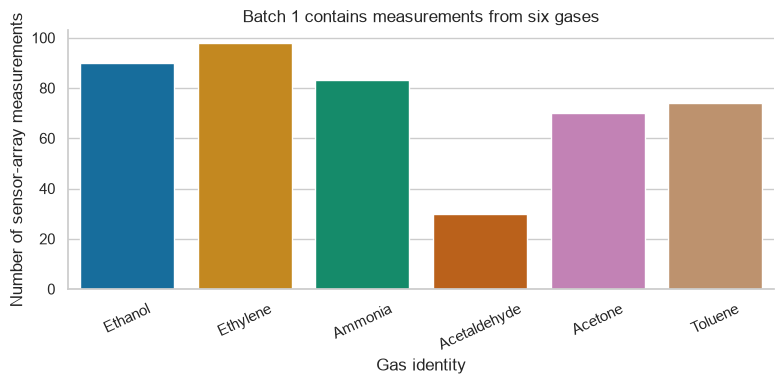

In [5]:
class_counts = (
    data["gas"]
    .value_counts()
    .reindex(GAS_ORDER)
    .rename("observations")
    .to_frame()
)
display(class_counts)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    x=class_counts.index,
    y=class_counts["observations"],
    hue=class_counts.index,
    palette=GAS_PALETTE,
    legend=False,
    ax=ax,
)
ax.set(
    title="Batch 1 contains measurements from six gases",
    xlabel="Gas identity",
    ylabel="Number of sensor-array measurements",
)
ax.tick_params(axis="x", rotation=25)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

In [6]:
# Summarize the steady-state ΔR readings for the first eight sensors.
# Sensor responses have very different scales, so standardization matters.
sensor_summary = data[FEATURE_NAMES[:8]].describe().T[
    ["min", "50%", "mean", "std", "max"]
]
display(sensor_summary.rename(columns={"50%": "median"}))

print(f"Missing feature values: {data[FEATURE_NAMES].isna().sum().sum()}")

,min,median,mean,std,max
Sensor 01 — ΔR steady state,-518.4101,73888.5136,125598.154467,154508.292267,670687.3477
Sensor 02 — ΔR steady state,-40.1308,69638.8721,107079.558616,121831.976951,502202.8125
Sensor 03 — ΔR steady state,185.4209,13941.1028,15899.626989,10649.316150,46951.1560
Sensor 04 — ΔR steady state,166.7058,14520.8052,15560.009038,10040.609175,42158.8628
Sensor 05 — ΔR steady state,0.6032,3376.5931,3920.788642,2580.710737,11857.4483
Sensor 06 — ΔR steady state,3.2514,3801.7436,4471.045329,2994.299294,13800.2196
Sensor 07 — ΔR steady state,112.4736,13491.3383,16272.603087,10756.149928,56038.4097
Sensor 08 — ΔR steady state,114.5823,14356.2158,16686.199159,10815.786926,54877.9287


Missing feature values: 0


## 3. Hold out data before ranking features or fitting PCA

We will use a stratified 70/30 train/test split. Stratification preserves each gas's approximate share in both sets. We fit the feature-ranking model, feature scaler, PCA, and classifiers using the training data only; the test data is held back until evaluation.

In [7]:
train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

train_counts = pd.Series(y_train).value_counts().reindex(GAS_NAMES)
test_counts = pd.Series(y_test).value_counts().reindex(GAS_NAMES)
split_summary = pd.DataFrame(
    {
        "training samples": train_counts.to_numpy(),
        "test samples": test_counts.to_numpy(),
    },
    index=GAS_ORDER,
)
display(split_summary)
print(f"Training: {len(train_idx)} rows; test: {len(test_idx)} rows")

,training samples,test samples
Ethanol,63,27
Ethylene,68,30
Ammonia,58,25
Acetaldehyde,21,9
Acetone,49,21
Toluene,52,22


Training: 311 rows; test: 134 rows


## 4. Which two sensor readings look most informative?

A forest-style ensemble of randomized decision trees can estimate how much each sensor's steady-state reading helps reduce class mixing at tree splits. We fit the ensemble on the training set, then rank the 16 sensor readings by impurity-based importance.

This ranking is only a convenient way to choose a raw two-feature view. It is not a causal explanation, and correlated sensor readings can share or trade importance. The ranking itself is supervised because it uses the training labels.

In [8]:
feature_ranker = ExtraTreesClassifier(
    n_estimators=500,
    max_features="sqrt",
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
feature_ranker.fit(X_train, y_train)

importance = pd.DataFrame(
    {
        "source_feature_number": STEADY_STATE_INDICES + 1,
        "sensor": np.arange(1, X.shape[1] + 1),
        "feature": FEATURE_NAMES,
        "importance": feature_ranker.feature_importances_,
    }
).sort_values("importance", ascending=False, ignore_index=True)

top_two_features = importance.loc[:1, "feature"].tolist()
top_two_indices = [FEATURE_NAMES.index(name) for name in top_two_features]

display(importance.head(10))
print("Selected raw features:")
for row in importance.head(2).itertuples(index=False):
    print(f"  Sensor {row.sensor} (raw feature {row.source_feature_number}): {row.feature}")

,source_feature_number,sensor,feature,importance
0,9,2,Sensor 02 — ΔR steady state,0.125503
1,65,9,Sensor 09 — ΔR steady state,0.125343
2,73,10,Sensor 10 — ΔR steady state,0.121302
3,1,1,Sensor 01 — ΔR steady state,0.111300
4,41,6,Sensor 06 — ΔR steady state,0.056695
5,33,5,Sensor 05 — ΔR steady state,0.054705
6,97,13,Sensor 13 — ΔR steady state,0.047079
7,105,14,Sensor 14 — ΔR steady state,0.044960
8,17,3,Sensor 03 — ΔR steady state,0.043747
9,25,4,Sensor 04 — ΔR steady state,0.043452


Selected raw features:
  Sensor 2 (raw feature 9): Sensor 02 — ΔR steady state
  Sensor 9 (raw feature 65): Sensor 09 — ΔR steady state


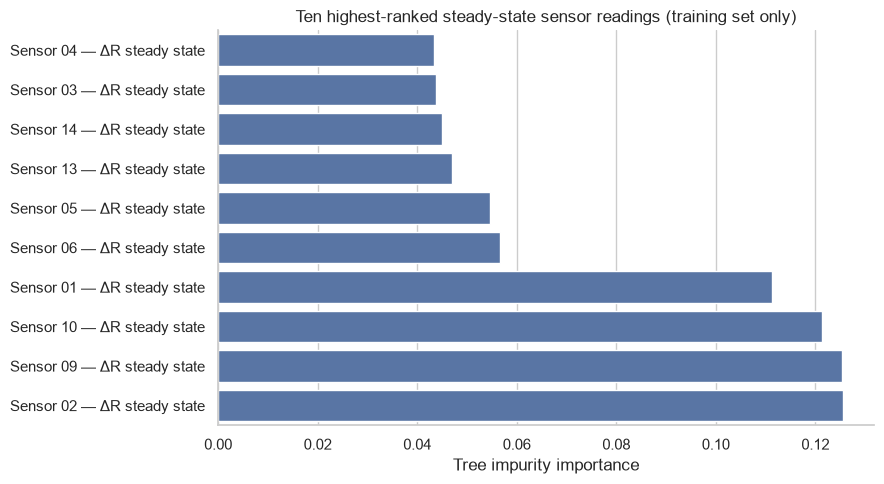

In [9]:
top_features = importance.head(10).sort_values("importance")
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=top_features,
    x="importance",
    y="feature",
    color=sns.color_palette("deep")[0],
    ax=ax,
)
ax.set(
    title="Ten highest-ranked steady-state sensor readings (training set only)",
    xlabel="Tree impurity importance",
    ylabel="",
)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

Before PCA, plot the two selected sensor readings. We standardize these two axes so their scales are comparable. The plot is colored by gas identity; the labels are added for interpretation, not to construct these coordinates.

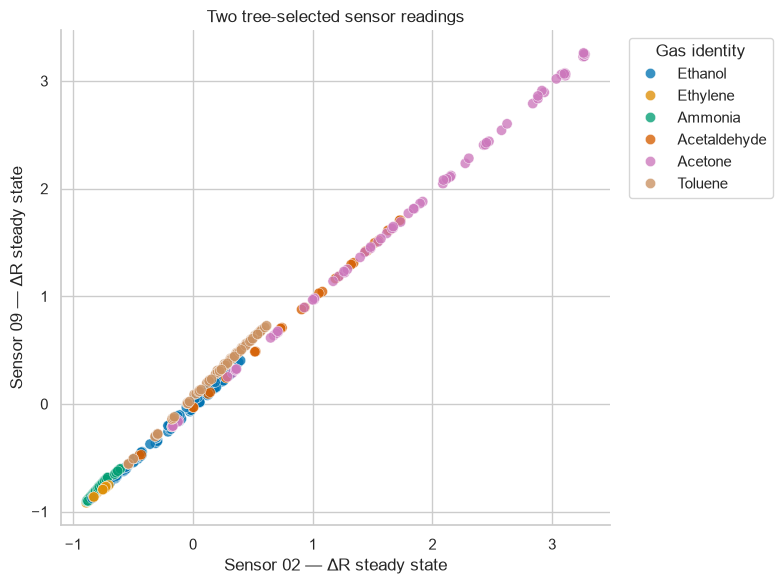

In [10]:
raw_pair_scaler = StandardScaler().fit(X_train[:, top_two_indices])
raw_pair_all = raw_pair_scaler.transform(X[:, top_two_indices])

raw_plot = pd.DataFrame(
    {
        "x": raw_pair_all[:, 0],
        "y": raw_pair_all[:, 1],
        "gas": pd.Series(y).map(GAS_NAMES).to_numpy(),
    }
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=raw_plot,
    x="x",
    y="y",
    hue="gas",
    hue_order=GAS_ORDER,
    palette=GAS_PALETTE,
    s=55,
    alpha=0.78,
    edgecolor="white",
    linewidth=0.4,
    ax=ax,
)
ax.set(
    title="Two tree-selected sensor readings",
    xlabel=top_two_features[0],
    ylabel=top_two_features[1],
)
ax.legend(title="Gas identity", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## 5. Fit PCA on the 16 sensor readings

PCA looks for directions that capture variation across the **whole 16-sensor matrix**. Sensor responses have different scales, so we standardize each feature using the training set's mean and standard deviation. Then PCA is fitted to the standardized training observations, without labels.

We keep the first four components so we can compare models using the first 2, 3, and 4 PCs.

In [11]:
feature_scaler = StandardScaler().fit(X_train)
X_train_scaled = feature_scaler.transform(X_train)
X_test_scaled = feature_scaler.transform(X_test)
X_all_scaled = feature_scaler.transform(X)

pca = PCA(n_components=4, random_state=RANDOM_STATE)
PC_train = pca.fit_transform(X_train_scaled)
PC_test = pca.transform(X_test_scaled)
PC_all = pca.transform(X_all_scaled)

variance_table = pd.DataFrame(
    {
        "component": [f"PC{i}" for i in range(1, 5)],
        "variance explained": pca.explained_variance_ratio_,
        "cumulative variance": np.cumsum(pca.explained_variance_ratio_),
    }
)
display(variance_table.assign(
    **{
        column: variance_table[column].map("{:.1%}".format)
        for column in ["variance explained", "cumulative variance"]
    }
))

,component,variance explained,cumulative variance
0,PC1,67.0%,67.0%
1,PC2,23.9%,91.0%
2,PC3,8.4%,99.3%
3,PC4,0.4%,99.8%


The next plot shows how much variation each of the first four directions explains. The principal components are combinations of the 16 sensor readings; no gas labels were used to compute them.

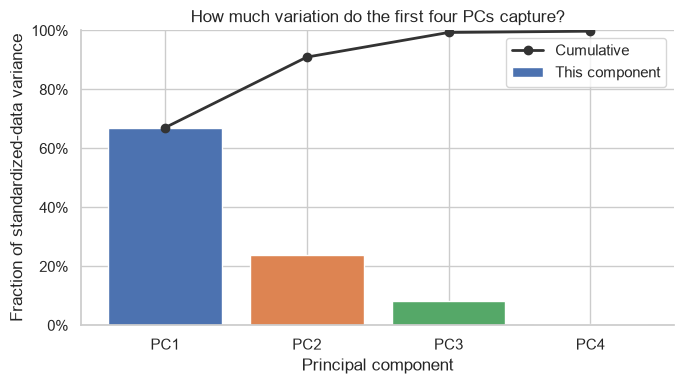

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
component_labels = variance_table["component"]
ax.bar(
    component_labels,
    variance_table["variance explained"],
    color=sns.color_palette("deep")[:4],
    label="This component",
)
ax.plot(
    component_labels,
    variance_table["cumulative variance"],
    color="#333333",
    marker="o",
    linewidth=2,
    label="Cumulative",
)
ax.set(
    title="How much variation do the first four PCs capture?",
    xlabel="Principal component",
    ylabel="Fraction of standardized-data variance",
    ylim=(0, 1),
)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend()
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## 6. Does the new representation help a simple classifier?

To separate the effect of representation from the effect of changing model families, we use the **same logistic-regression classifier** for every comparison:

- the two steady-state sensor readings selected by the tree ensemble;
- the first 2 PCs;
- the first 3 PCs;
- the first 4 PCs.

The PC scores use the PCA model fitted on training data. The raw pair is standardized separately, also using training data only. Class weights are balanced because the gas counts differ. We report balanced accuracy, ordinary accuracy, and macro F1.

In [13]:
classifier_options = {
    "C": 10,
    "class_weight": "balanced",
    "max_iter": 5_000,
}

raw_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(**classifier_options),
)
raw_model.fit(X_train[:, top_two_indices], y_train)
raw_prediction = raw_model.predict(X_test[:, top_two_indices])

representations = [
    ("Two sensor readings", raw_prediction),
]
pc_models = {}

for n_components in (2, 3, 4):
    model = LogisticRegression(**classifier_options)
    model.fit(PC_train[:, :n_components], y_train)
    prediction = model.predict(PC_test[:, :n_components])
    pc_models[n_components] = model
    representations.append((f"First {n_components} PCs", prediction))

score_rows = []
for name, prediction in representations:
    score_rows.append(
        {
            "representation": name,
            "balanced accuracy": balanced_accuracy_score(y_test, prediction),
            "accuracy": accuracy_score(y_test, prediction),
            "macro F1": f1_score(y_test, prediction, average="macro"),
        }
    )

scores = pd.DataFrame(score_rows)
display(scores.round(3))

,representation,balanced accuracy,accuracy,macro F1
0,Two sensor readings,0.573,0.597,0.570
1,First 2 PCs,0.926,0.925,0.921
2,First 3 PCs,0.955,0.955,0.947
3,First 4 PCs,0.955,0.955,0.947


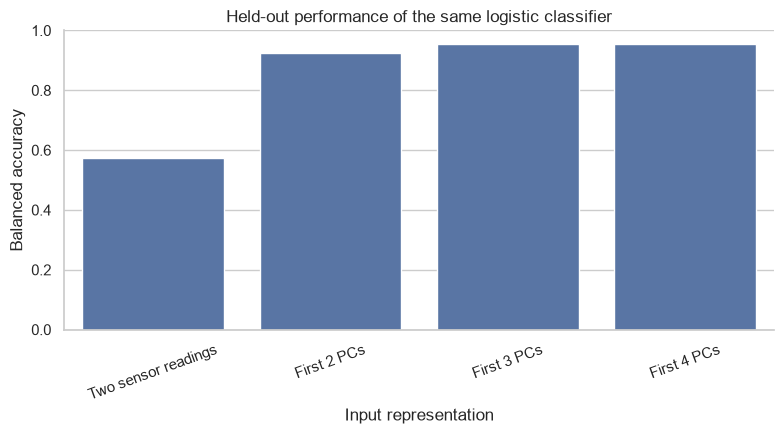

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=scores,
    x="representation",
    y="balanced accuracy",
    color=sns.color_palette("deep")[0],
    ax=ax,
)
ax.set(
    title="Held-out performance of the same logistic classifier",
    xlabel="Input representation",
    ylabel="Balanced accuracy",
    ylim=(0, 1),
)
ax.tick_params(axis="x", rotation=20)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## 7. The money plot: the same samples in two different views

The left panel uses the two steady-state sensor readings selected by the tree ensemble. The right panel projects all 16 standardized sensor readings onto PC1 and PC2. The scaling and PCA directions were fit on training data only; both train and test observations are shown.

The gas labels are used only for the colors in these scatterplots. PCA does not know which dot is ethanol, ammonia, or any other class.

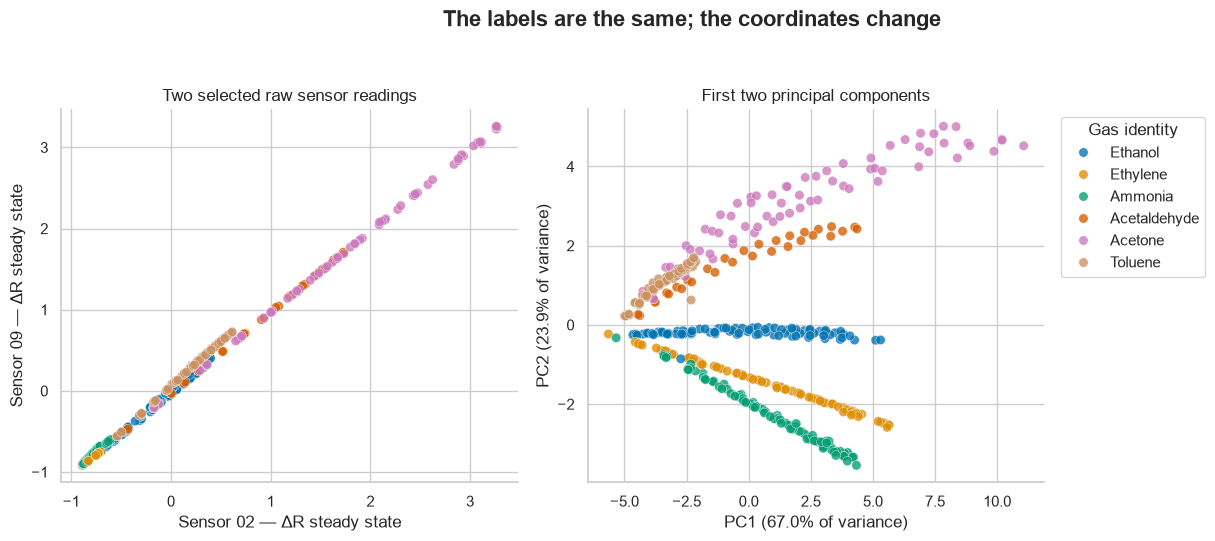

In [15]:
money_plot = pd.DataFrame(
    {
        "raw_x": raw_pair_all[:, 0],
        "raw_y": raw_pair_all[:, 1],
        "PC1": PC_all[:, 0],
        "PC2": PC_all[:, 1],
        "gas": pd.Series(y).map(GAS_NAMES).to_numpy(),
    }
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.scatterplot(
    data=money_plot,
    x="raw_x",
    y="raw_y",
    hue="gas",
    hue_order=GAS_ORDER,
    palette=GAS_PALETTE,
    s=46,
    alpha=0.78,
    edgecolor="white",
    linewidth=0.35,
    legend=False,
    ax=axes[0],
)
axes[0].set(
    title="Two selected raw sensor readings",
    xlabel=top_two_features[0],
    ylabel=top_two_features[1],
)

sns.scatterplot(
    data=money_plot,
    x="PC1",
    y="PC2",
    hue="gas",
    hue_order=GAS_ORDER,
    palette=GAS_PALETTE,
    s=46,
    alpha=0.78,
    edgecolor="white",
    linewidth=0.35,
    ax=axes[1],
)
axes[1].set(
    title="First two principal components",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)",
)
axes[1].legend(title="Gas identity", bbox_to_anchor=(1.02, 1), loc="upper left")

fig.suptitle(
    "The labels are the same; the coordinates change",
    fontsize=16,
    fontweight="bold",
)
sns.despine()
fig.tight_layout(rect=(0, 0, 0.88, 0.94))
plt.show()

### How to read the money plot

- Each point is one gas exposure measured by the sensor array.
- The left plot keeps just two original sensor measurements. Their label colors overlap substantially.
- The right plot combines the 16 sensor readings into two new coordinates. The gas-related structure is easier to see.
- This is a visualization result, not a promise that PCA always improves class recognition. PCA maximizes variance, not class separation; the score table is a separate, held-out check using labels.
- Different gas concentrations and response dynamics are part of this experiment. Do not interpret the picture as proof that PCA isolates gas identity independently of concentration.

A follow-up in class can hide the labels, run a clustering method on PC1 and PC2, then reveal the known gas identities to inspect how the discovered groups align.

## Takeaways

- One observation can be represented by a 128-feature sensor fingerprint; this notebook uses one steady-state reading from each of the 16 sensors for the comparison.
- A pair of individually useful original measurements does not necessarily provide a useful 2D map.
- PCA combines information across many correlated features into new directions.
- On this dataset, a simple classifier improves when given more of the leading PCs, but the PCA plot itself was created without labels.
- After viewing the map, clustering can be introduced as the next question: can an algorithm recover groups without being told the gas identities?

**Source:** Alexander Vergara, [Gas Sensor Array Drift Dataset](https://doi.org/10.24432/C5RP6W), UCI Machine Learning Repository. The dataset is provided under CC BY 4.0; cite the repository record when reusing it.

[← Return to the course home](../index.qmd)